<a href="https://colab.research.google.com/github/EmiiFernandez/actividades_data_sciente_ypf/blob/main/notebook/C32_Notebook-36.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

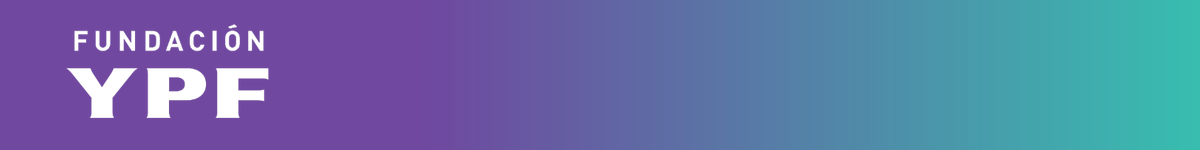

# Fundación YPF - Data Science

## Notebook 36: Cierre integrador del curso y repaso para la presentación de proyectos

### Índice de partes

* **Parte 0:** Por qué este notebook es distinto y cómo usarlo
* **Parte 1:** Carga y repaso de Análisis Exploratorio de Datos
* **Parte 2:** Repaso de Aprendizaje No Supervisado: Clustering con K-Means y evaluación con Silhouette
* **Parte 3:** Repaso de Aprendizaje Supervisado y Redes Neuronales: clasificación con un Perceptrón Multicapa (MLP)
* **Parte 4:** Cierre: qué llevarse a la presentación de proyectos

## Parte 0: Por qué este notebook es distinto y cómo usarlo

Esta es la clase de cierre del curso: hoy presentan sus proyectos finales. No hay teoría nueva para aplicar, así que este notebook no sigue el formato habitual de "teoría nueva mas notebook de aplicación".

En cambio, es un **repaso integrador** de dos de las técnicas más importantes que vimos a lo largo del curso, ejecutado de punta a punta sobre un dataset que ya usamos antes (`cancer_mamario.csv`, de las Notebooks 27 a 32). La idea es que lo tengan como material de consulta rápida antes de armar su propia presentación:

* **Parte 2:** Aprendizaje No Supervisado, clustering con K-Means y cómo evaluarlo con el método del codo y el coeficiente de Silhouette (Notebooks 23 a 26).
* **Parte 3:** Aprendizaje Supervisado y Redes Neuronales, clasificación con un Perceptrón Multicapa, preprocesamiento, entrenamiento y evaluación con métricas de clasificación (Notebooks 25 a 32).

No incluye un ejercicio nuevo para las salas de Zoom: la actividad de hoy es la presentación de los proyectos, no una práctica guiada. Si quieren repasar con un ejercicio para completar, los de las Notebooks 26 y 32 (clustering sobre `blackfriday.csv` y MLP sobre `StudentsPerformance.csv`) siguen siendo un buen punto de partida.

Antes de ejecutar, suban el archivo `cancer_mamario.csv` al panel de archivos de Colab (ícono de carpeta a la izquierda).

In [ ]:
import os
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## Parte 1: Carga y repaso de Análisis Exploratorio de Datos

Usamos `cancer_mamario.csv`, el mismo dataset de las Notebooks 27 a 32. Cada fila es una paciente, con variables clínicas (edad, tamaño del tumor, cantidad de ganglios afectados, etc.) y la columna `class` indica si tuvo recurrencia del cáncer o no.

In [ ]:
if not os.path.exists("cancer_mamario.csv"):
    from google.colab import files
    files.upload()

cancer = pd.read_csv("cancer_mamario.csv")
print(cancer.shape)
cancer.head()

(286, 10)


,class,age,menopause,tumor-size,inv-nodes,node-caps,deg-malig,breast,breast-quad,irradiat
0,no-recurrence-events,30-39,premeno,30-34,0-2,no,3,left,left_low,no
1,no-recurrence-events,40-49,premeno,20-24,0-2,no,2,right,right_up,no
2,no-recurrence-events,40-49,premeno,20-24,0-2,no,2,left,left_low,no
3,no-recurrence-events,60-69,ge40,15-19,0-2,no,2,right,left_up,no
4,no-recurrence-events,40-49,premeno,0-4,0-2,no,2,right,right_low,no


class
no-recurrence-events    201
recurrence-events        85
Name: count, dtype: int64


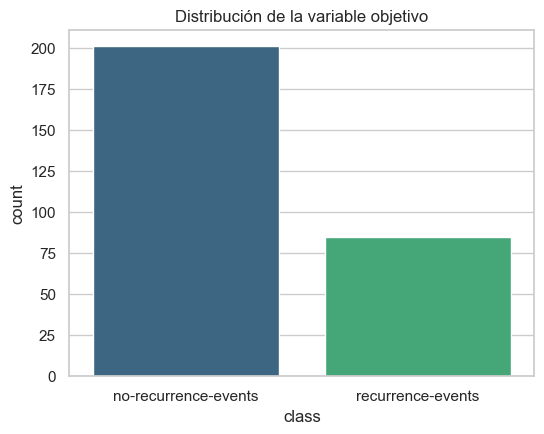

In [ ]:
print(cancer["class"].value_counts())

plt.figure(figsize=(6, 4.5))
sns.countplot(data=cancer, x="class", hue="class", palette="viridis", legend=False)
plt.title("Distribución de la variable objetivo")
plt.show()

Como ya vimos en la Notebook 32, el dataset está desbalanceado: hay más pacientes sin recurrencia que con recurrencia. Lo tenemos en cuenta más adelante al dividir en entrenamiento y prueba (`stratify`) y al leer las métricas de clasificación.

### Preprocesamiento

Sacamos las filas con valores faltantes (marcados como `?`), codificamos las variables categóricas de forma numérica y escalamos las variables con `StandardScaler`. Este preprocesamiento es el que necesitan tanto el clustering (Parte 2) como la red neuronal (Parte 3).

In [ ]:
filas_antes = len(cancer)
cancer_limpio = cancer[(cancer != "?").all(axis=1)].copy()
print(f"Filas antes de sacar los '?': {filas_antes}")
print(f"Filas después: {len(cancer_limpio)}")

cancer_cod = cancer_limpio.copy()
codificadores = {}
for columna in cancer_cod.columns:
    if cancer_cod[columna].dtype == "object":
        le = LabelEncoder()
        cancer_cod[columna] = le.fit_transform(cancer_cod[columna])
        codificadores[columna] = le

X = cancer_cod.drop(columns=["class"])
y = cancer_cod["class"]

escalador = StandardScaler()
X_esc = escalador.fit_transform(X)
print(X_esc.shape)

Filas antes de sacar los '?': 286
Filas después: 277
(277, 9)


## Parte 2: Repaso de Aprendizaje No Supervisado: Clustering con K-Means y Silhouette

En las Notebooks 23 a 26 agrupamos clientes con K-Means y DBSCAN, y aprendimos a elegir el número de clusters con el método del codo y a evaluar el resultado con el coeficiente de Silhouette. Repetimos ese procedimiento acá, ahora sobre las variables clínicas de `cancer_mamario.csv` (sin usar la columna `class`, que es la que intentamos predecir en la Parte 3).

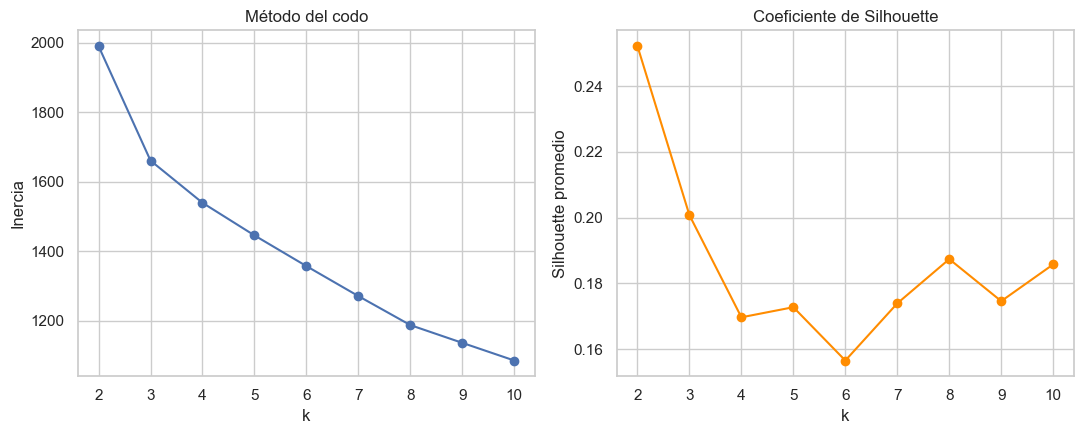

k con mejor Silhouette: 2


In [ ]:
valores_k = range(2, 11)
inercias = [KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_esc).inertia_ for k in valores_k]
siluetas = [
    silhouette_score(X_esc, KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_esc))
    for k in valores_k
]

fig, ejes = plt.subplots(1, 2, figsize=(11, 4.5))
ejes[0].plot(list(valores_k), inercias, marker="o")
ejes[0].set_title("Método del codo")
ejes[0].set_xlabel("k")
ejes[0].set_ylabel("Inercia")

ejes[1].plot(list(valores_k), siluetas, marker="o", color="darkorange")
ejes[1].set_title("Coeficiente de Silhouette")
ejes[1].set_xlabel("k")
ejes[1].set_ylabel("Silhouette promedio")
plt.tight_layout()
plt.show()

mejor_k = list(valores_k)[int(np.argmax(siluetas))]
print(f"k con mejor Silhouette: {mejor_k}")

In [ ]:
kmeans_final = KMeans(n_clusters=mejor_k, n_init=10, random_state=RANDOM_STATE).fit(X_esc)
silhouette_final = silhouette_score(X_esc, kmeans_final.labels_)
print(f"Silhouette con k={mejor_k}: {silhouette_final:.3f}")

cancer_cod["cluster"] = kmeans_final.labels_
pd.crosstab(cancer_cod["cluster"], cancer_limpio["class"])

Silhouette con k=2: 0.252


class,no-recurrence-events,recurrence-events
cluster,,
0,168,42
1,28,39


El mejor valor de Silhouette se obtiene con k=2 (Silhouette = 0.252), un valor moderado a bajo: indica que hay algo de estructura en las variables clínicas, pero los grupos no quedan tan compactos y separados como en el ejemplo de clientes de un centro comercial (Notebooks 23 a 26). La tabla cruzada muestra que el cluster 0 concentra la mayoría de las pacientes sin recurrencia (168 de 210 en ese cluster), mientras que el cluster 1 queda más parejo entre ambas clases (28 sin recurrencia y 39 con recurrencia). Hay cierta relación entre los clusters y la clase real, pero no es una separación perfecta, algo esperable: el clustering es no supervisado, nunca vio la columna class durante el ajuste, solo agrupa pacientes parecidas según sus variables clínicas.

## Parte 3: Repaso de Aprendizaje Supervisado y Redes Neuronales: clasificación con un MLP

En las Notebooks 25 a 32 vimos la teoría de redes neuronales (neurona, perceptrón simple y multicapa, descenso por gradiente, funciones de activación) y la aplicamos con `MLPClassifier` de scikit-learn. Repetimos acá ese flujo completo: separar en entrenamiento y prueba, escalar, entrenar y evaluar.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

escalador_mlp = StandardScaler()
X_train_esc = escalador_mlp.fit_transform(X_train)
X_test_esc = escalador_mlp.transform(X_test)
print(X_train_esc.shape, X_test_esc.shape)

(207, 9) (70, 9)


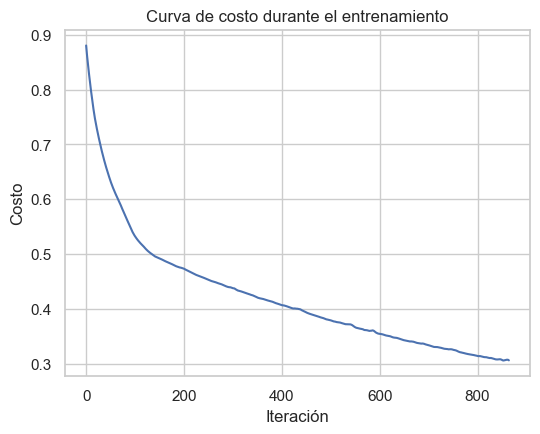

In [ ]:
mlp = MLPClassifier(
    hidden_layer_sizes=(16, 8),
    activation="relu",
    solver="adam",
    max_iter=1000,
    random_state=RANDOM_STATE,
)
mlp.fit(X_train_esc, y_train)

plt.figure(figsize=(6, 4.5))
plt.plot(mlp.loss_curve_)
plt.title("Curva de costo durante el entrenamiento")
plt.xlabel("Iteración")
plt.ylabel("Costo")
plt.show()

Exactitud en prueba: 0.757
              precision    recall  f1-score   support

           0       0.81      0.86      0.83        50
           1       0.59      0.50      0.54        20

    accuracy                           0.76        70
   macro avg       0.70      0.68      0.69        70
weighted avg       0.75      0.76      0.75        70



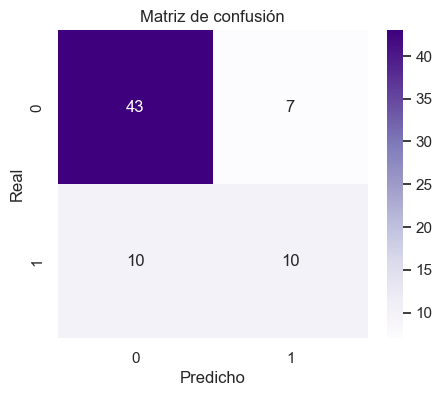

In [ ]:
y_pred = mlp.predict(X_test_esc)

exactitud = accuracy_score(y_test, y_pred)
print(f"Exactitud en prueba: {exactitud:.3f}")
print(classification_report(y_test, y_pred))

matriz = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(matriz, annot=True, fmt="d", cmap="Purples")
plt.title("Matriz de confusión")
plt.xlabel("Predicho")
plt.ylabel("Real")
plt.show()

El MLP llega a una exactitud de 0.757 en el conjunto de prueba. Pero, como ya vimos en la clase de evaluación de modelos, la exactitud sola no alcanza en un dataset desbalanceado (201 pacientes sin recurrencia contra 85 con recurrencia). El classification_report lo deja claro: para la clase sin recurrencia el modelo tiene precision 0.81 y recall 0.86, pero para la clase con recurrencia baja a precision 0.59 y recall 0.50. Es decir, de cada dos pacientes que realmente tuvieron recurrencia, el modelo detecta una sola. La matriz de confusión muestra lo mismo de forma visual. Para un caso de uso real como este, donde el costo de no detectar una recurrencia es alto, conviene mirar precision y recall por clase (y no solo la exactitud general) antes de dar un modelo por bueno, tal como se discutió en las clases de evaluación de modelos y de redes neuronales.

## Parte 4: Cierre, qué llevarse a la presentación de proyectos

Repasamos hoy las dos grandes familias de técnicas del curso sobre el mismo dataset:

* **Aprendizaje No Supervisado** (Parte 2): agrupar datos sin una etiqueta, eligiendo el número de clusters con el método del codo y validando con Silhouette.
* **Aprendizaje Supervisado y Redes Neuronales** (Parte 3): predecir una etiqueta a partir de datos de entrenamiento, con un Perceptrón Multicapa, y evaluar el resultado con exactitud, reporte de clasificación y matriz de confusión.

Para la presentación de su propio proyecto, estas son las mismas preguntas que conviene responder: qué problema eligieron, qué encontraron en el análisis exploratorio, qué preprocesamiento necesitaron, qué modelo(s) entrenaron y cómo evaluaron si el resultado es bueno. Mucha suerte presentando, y felicidades por llegar al final del curso.